<a href="https://colab.research.google.com/github/shahbazmaryam25/Data-Science-and-Generative-AI/blob/main/week_4_4_01_decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler

# import the data
data = load_breast_cancer()

# create a DataFrame of features
x_values = pd.DataFrame(data.data, columns=data.feature_names)

# create a MinMaxScaler object and transform data
scaler = MinMaxScaler()
normal_data = scaler.fit_transform(x_values)
x_values = pd.DataFrame(normal_data, columns=data.feature_names)

# create y value
y_value = pd.DataFrame(data.target, columns=['class'])
y_value = np.ravel(y_value)

In [ ]:
from sklearn.model_selection import train_test_split

# split data into training and test sets with stratification
X_train, X_test, Y_train, Y_test = train_test_split(
    x_values, y_value, test_size=0.2, random_state=1984, stratify=y_value
)

# print shapes to check
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
Y_train shape: (455,)
Y_test shape: (114,)


Initial Model Accuracy: 0.92


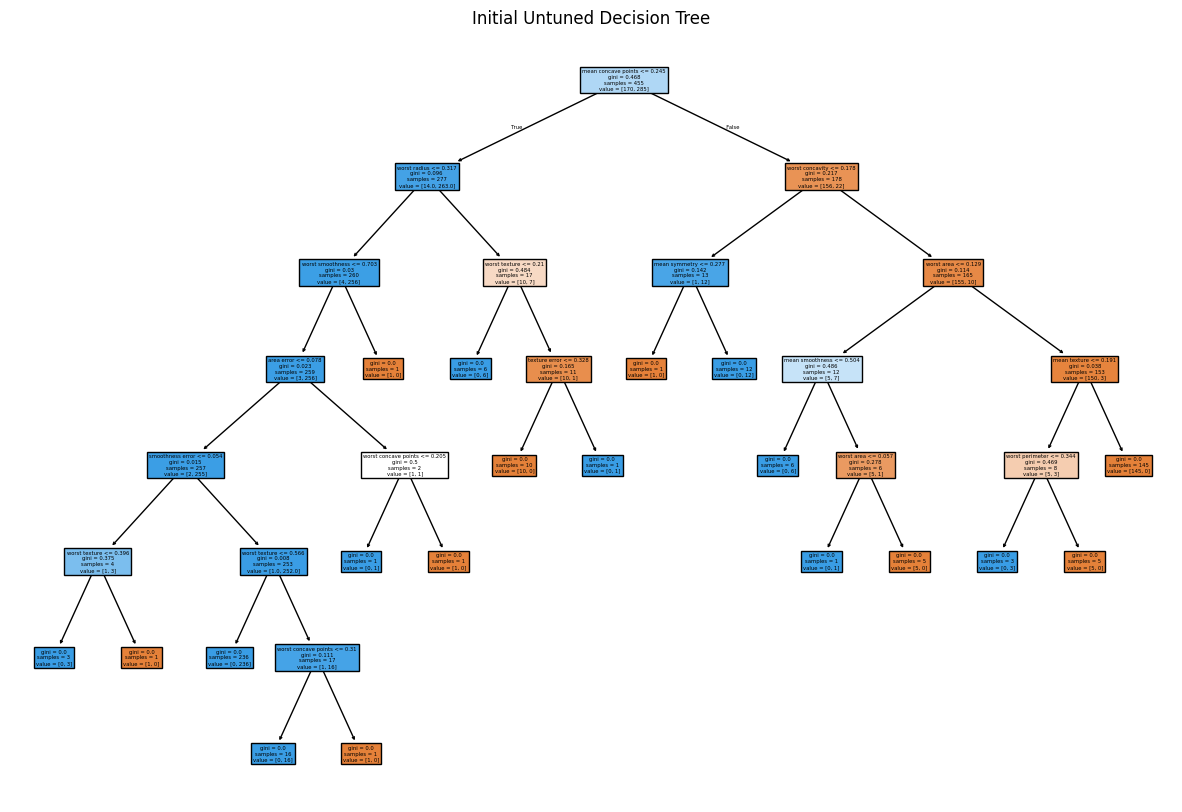

In [ ]:
from sklearn.tree import DecisionTreeClassifier as DTC, plot_tree
from sklearn.metrics import accuracy_score

# create and fit the initial model
DTC_algo = DTC()
DTC_model = DTC_algo.fit(X_train, Y_train)

# predict test data
predict = DTC_model.predict(X_test)

print(f'Initial Model Accuracy: {round(accuracy_score(Y_test, predict), 2)}')

# plot the large, untuned tree
plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.title("Initial Untuned Decision Tree")
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# define parameters to tune
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),
    'min_samples_split': randint(3, 9),
    'max_features': ['sqrt', 'log2', None]
}

score = 'f1_macro'
print(f"Tuning hyperparameters for {score}...\n")

# set up search
clf = RandomizedSearchCV(
    DTC(), tuned_parameters, cv=5, random_state=1984,
    scoring=score, n_iter=20, refit=True
)

# fit search against training data
clf.fit(X_train, Y_train)

print("Best parameters set found on the training set:")
print(clf.best_params_)

Tuning hyperparameters for f1_macro...

Best parameters set found on the training set:
{'criterion': 'gini', 'max_depth': 4, 'max_features': None, 'min_samples_split': 3}


Tuned Model Accuracy: 0.95



<Figure size 600x600 with 0 Axes>

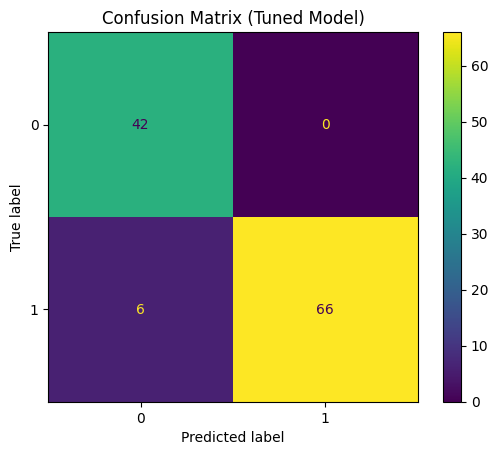

Micro-averaged Precision: 0.95
Micro-averaged Recall: 0.95
Micro-averaged F1-score: 0.95

Macro-averaged Precision: 0.94
Macro-averaged Recall: 0.96
Macro-averaged F1-score: 0.94



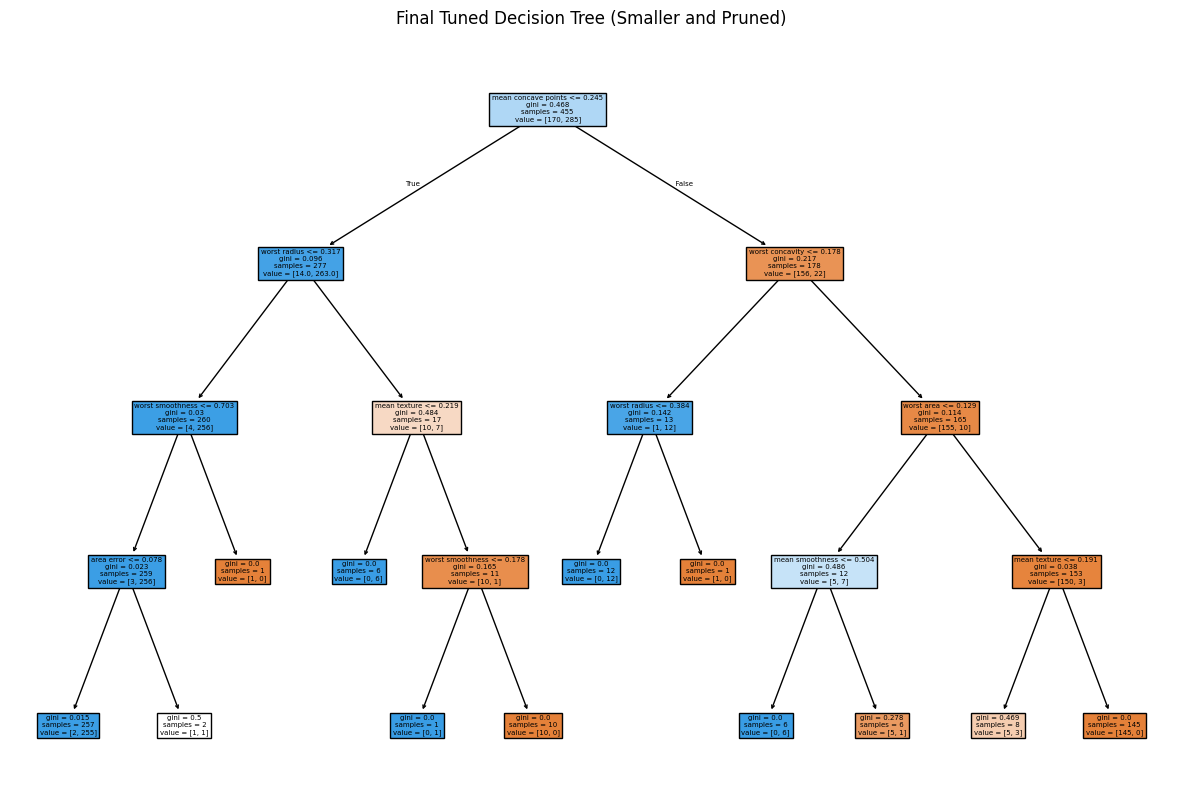

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay as CM, precision_recall_fscore_support

# Extract the best tuned model automatically using best_estimator_
DTC_model_tuned = clf.best_estimator_

# Predict using the tuned model
predict = DTC_model_tuned.predict(X_test)

print(f'Tuned Model Accuracy: {round(accuracy_score(Y_test, predict), 2)}\n')

# Confusion Matrix
plt.figure(figsize=(6, 6))
CM.from_predictions(Y_test, predict)
plt.title("Confusion Matrix (Tuned Model)")
plt.show()

# Micro-averaged metrics
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')
print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}\n")

# Macro-averaged metrics
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}\n")

# Plot the final, smaller tuned tree
plt.figure(figsize=(15, 10))
plot_tree(DTC_model_tuned, filled=True, feature_names=X_train.columns)
plt.title("Final Tuned Decision Tree (Smaller and Pruned)")
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score, classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier

# Define the model
DTC_model = DecisionTreeClassifier(random_state=1984)

# Choose settings to test
param_grid = {
    'max_depth': [None, 3, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

# Find the settings that maximise macro recall
grid_search = GridSearchCV(
    DTC_model,
    param_grid,
    scoring='recall_macro',
    cv=5
)

grid_search.fit(X_train, Y_train)

# Keep the best model
DTC_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro recall:", round(grid_search.best_score_, 2))


Best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best cross-validation macro recall: 0.93


In [ ]:
predict = DTC_model.predict(X_test)

print("Accuracy:", round(accuracy_score(Y_test, predict), 2))
print("Macro recall:", round(recall_score(Y_test, predict, average='macro'), 2))

print(classification_report(Y_test, predict))

Accuracy: 0.96
Macro recall: 0.97
              precision    recall  f1-score   support

           0       0.89      1.00      0.94        42
           1       1.00      0.93      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.97      0.95       114
weighted avg       0.96      0.96      0.96       114



Macro recall calculates recall separately for each class and then takes the average, giving both classes equal importance.

Accuracy measures the proportion of all predictions that are correct.

After optimisation, macro recall may improve, but accuracy may decrease. This is because the model is prioritising identifying cases from both classes rather than simply maximising the total number of correct predictions.